# Question 2 — Gender Differences in Stress Level (based on social-media usage)

**Research question:** Is there a difference in **stress level** between men and women,
based on their social-media usage data? Does gender affect the **stress level** and the
**mental-health score**, or is there no relationship between the variables?

We examine whether **gender** is associated with differences in **stress level** and
**mental-health score**, using contingency-table tests, group comparisons with effect
sizes, a usage-based subgroup breakdown, and a control check that isolates the effect of
gender after accounting for social-media usage.

## 0. Setup & Data Loading

In [12]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

# Cleaned dataset exported by data_exploration/01_data_overview_and_distributions.ipynb
# (exact duplicate rows removed, negative values clipped to 0)
DATA_PATH = '../dataset/student_social_media_cleaned.csv'
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f'{DATA_PATH} not found — run data_exploration/01_data_overview_and_distributions.ipynb first'
    )
df = pd.read_csv(DATA_PATH)

STRESS_ORDER = ['Low', 'Medium', 'High', 'Very High']
df['Stress_Level'] = pd.Categorical(df['Stress_Level'], categories=STRESS_ORDER, ordered=True)

# Ordinal encoding of stress (0..3) — same convention as data_exploration/02
stress_map = {lvl: i for i, lvl in enumerate(STRESS_ORDER)}
df['Stress_Level_Enc'] = df['Stress_Level'].map(stress_map).astype(int)

GENDER_COL  = 'Gender'
STRESS_COL  = 'Stress_Level'
MHS_COL     = 'Mental_Health_Score'
GENDER_PALETTE = {'Male': 'steelblue', 'Female': 'crimson'}

print('Shape:', df.shape)
print('\nGender counts:')
print(df[GENDER_COL].value_counts().to_string())
print('\nStress level counts:')
print(df[STRESS_COL].value_counts().reindex(STRESS_ORDER).to_string())

Shape: (4998, 14)

Gender counts:
Gender
Male      2634
Female    2364

Stress level counts:
Stress_Level
Low           643
Medium       1295
High         1439
Very High    1621


## 1. Why this is a group-comparison problem (and why effect sizes matter)

We are comparing **two groups** (Male vs Female) on two outcomes:

- **Stress level** — an *ordinal category*, so we use tests for categorical / ordinal data
  (Chi-square of independence, Mann–Whitney U on the ranks).
- **Mental-health score** — a *continuous* number, so we compare group means (t-test) and
  distributions (Mann–Whitney U).

## 2. Gender × Stress Level

**Understanding the p-value.** The *null hypothesis* of the Chi-square test of
independence is that **gender and stress level are independent** (knowing someone's gender
tells you nothing about their stress level). The **p-value** is the probability of seeing a
Gender × Stress association at least this strong by chance if that null were true.

- **p ≤ 0.05** → reject independence → the two variables are **associated**
- **p > 0.05** → not enough evidence of any association

Because Chi-square ignores the *order* of stress levels and is inflated by large n, we add
**Cramér's V** (effect size, 0–1) and a **Mann–Whitney U** test on the ordinal-encoded stress,
which respects the Low < Medium < High < Very High ordering.

In [13]:
# Contingency table: counts and row-normalised proportions
ct_counts = pd.crosstab(df[GENDER_COL], df[STRESS_COL])
ct_props  = pd.crosstab(df[GENDER_COL], df[STRESS_COL], normalize='index')

print('Contingency table (counts):')
print(ct_counts.to_string())
print('\nRow proportions (stress distribution within each gender):')
print((ct_props * 100).round(1).astype(str).add(' %').to_string())

Contingency table (counts):
Stress_Level  Low  Medium  High  Very High
Gender                                    
Female        301     564   719        780
Male          342     731   720        841

Row proportions (stress distribution within each gender):
Stress_Level     Low  Medium    High Very High
Gender                                        
Female        12.7 %  23.9 %  30.4 %    33.0 %
Male          13.0 %  27.8 %  27.3 %    31.9 %


In [14]:
def cramers_v(chi2, n, table_shape):
    """Cramer's V effect size from a chi-square statistic."""
    r, k = table_shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

def interpret_cramers_v(v):
    if v < 0.10: return 'negligible'
    if v < 0.30: return 'weak'
    if v < 0.50: return 'moderate'
    return 'strong'

def interpret_effect(a):
    """Generic |effect| label for rank-biserial / Cohen's d style magnitudes."""
    a = abs(a)
    if a < 0.10: return 'negligible'
    if a < 0.30: return 'small'
    if a < 0.50: return 'medium'
    return 'large'

# --- Chi-square test of independence + Cramer's V ---
chi2, chi_p, dof, _ = stats.chi2_contingency(ct_counts)
V = cramers_v(chi2, ct_counts.values.sum(), ct_counts.shape)

# --- Mann-Whitney U on ordinal stress (respects the ordering) ---
male_stress   = df.loc[df[GENDER_COL] == 'Male',   'Stress_Level_Enc']
female_stress = df.loc[df[GENDER_COL] == 'Female', 'Stress_Level_Enc']
u_stat, u_p = stats.mannwhitneyu(male_stress, female_stress, alternative='two-sided')
# rank-biserial correlation as the Mann-Whitney effect size
rank_biserial = 1 - (2 * u_stat) / (len(male_stress) * len(female_stress))

stress_results = pd.DataFrame({
    'Test':        ['Chi-square (independence)', 'Mann-Whitney U (ordinal)'],
    'Statistic':   [round(chi2, 3), round(u_stat, 1)],
    'p-value':     [chi_p, u_p],
    'Significant (α=0.05)': [chi_p < 0.05, u_p < 0.05],
    'Effect size': [f'V={V:.3f}', f'rank-biserial={rank_biserial:+.3f}'],
    'Magnitude':   [interpret_cramers_v(V), interpret_effect(rank_biserial)],
})
print(stress_results.to_string(index=False))
print(f'\nMean stress (encoded 0-3): Male={male_stress.mean():.3f}  Female={female_stress.mean():.3f}')

                     Test   Statistic  p-value  Significant (α=0.05)          Effect size  Magnitude
Chi-square (independence)      11.895 0.007751                  True              V=0.049 negligible
 Mann-Whitney U (ordinal) 3019418.000 0.054734                 False rank-biserial=+0.030 negligible

Mean stress (encoded 0-3): Male=1.782  Female=1.837


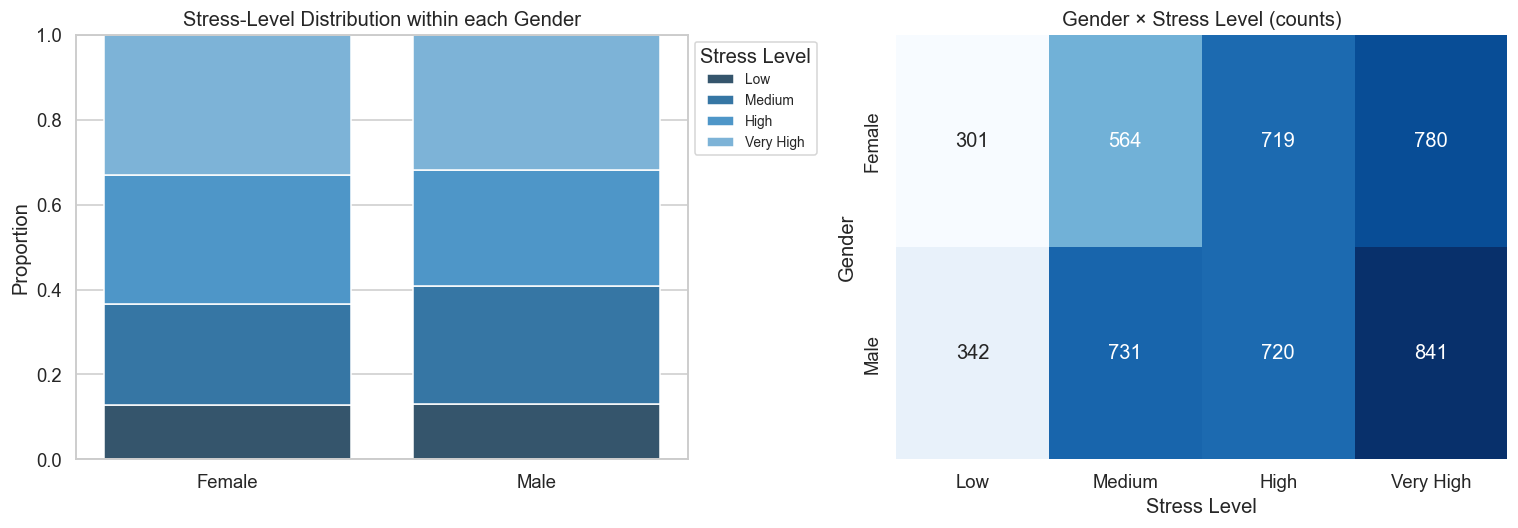

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1 — 100%-stacked bar of stress distribution within each gender
ax = axes[0]
bottom = np.zeros(len(ct_props))
blues = sns.color_palette('Blues_d', n_colors=len(STRESS_ORDER))[::-1]
for lvl, color in zip(STRESS_ORDER, blues):
    ax.bar(ct_props.index, ct_props[lvl], bottom=bottom, label=lvl, color=color, edgecolor='white')
    bottom += ct_props[lvl].values
ax.set_title('Stress-Level Distribution within each Gender')
ax.set_ylabel('Proportion')
ax.set_ylim(0, 1)
ax.legend(title='Stress Level', bbox_to_anchor=(1.0, 1.0), fontsize=9)

# Plot 2 — annotated heatmap of the contingency counts
ax = axes[1]
sns.heatmap(ct_counts, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
ax.set_title('Gender × Stress Level (counts)')
ax.set_xlabel('Stress Level')
ax.set_ylabel('Gender')

plt.tight_layout()
plt.show()

### What the results tell us

The two genders show **nearly identical** stress distributions — e.g. *Very High* is 33.0 %
of females vs 31.9 % of males, and *High* 30.4 % vs 27.3 %. The Chi-square test is
"significant" (p = 0.007), but this is exactly the large-n trap: **Cramér's V = 0.049 is
negligible**, so gender and stress level are **not meaningfully associated**. The Mann–Whitney
U is not even significant (p = 0.052) with a negligible rank-biserial (+0.031) — neither gender
tends toward higher stress ranks (mean encoded stress: Male 1.78 vs Female 1.84).

## 3. Gender × Mental-Health Score

**Understanding the p-value.** The *null hypothesis* of the independent t-test is that
the **two genders have the same mean mental-health score**. The **p-value** is the probability
of a mean difference at least this large by chance if that null were true.

- **p ≤ 0.05** → the mean difference is **statistically significant**
- **p > 0.05** → no evidence the means differ

We first check **normality** per gender (D'Agostino–Pearson) and **equal variances** (Levene)
to pick the right t-test variant, pair the test with **Cohen's d** (standardised mean gap), and
add a distribution-free **Mann–Whitney U** as a robustness check.

In [16]:
def cohens_d(a, b):
    """Cohen's d for two independent samples (pooled SD)."""
    na, nb = len(a), len(b)
    pooled_sd = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / pooled_sd

male_mhs   = df.loc[df[GENDER_COL] == 'Male',   MHS_COL]
female_mhs = df.loc[df[GENDER_COL] == 'Female', MHS_COL]

# Normality per gender
norm_rows = []
for g, vals in [('Male', male_mhs), ('Female', female_mhs)]:
    stat, p = stats.normaltest(vals)
    norm_rows.append({'Gender': g, 'normaltest stat': round(stat, 3), 'p-value': p,
                      'Distribution': 'Normal' if p > 0.05 else 'Not normal'})
print('Normality of Mental_Health_Score per gender:')
print(pd.DataFrame(norm_rows).to_string(index=False))

# Equal-variance (Levene) -> choose Student vs Welch
lev_stat, lev_p = stats.levene(male_mhs, female_mhs)
equal_var = lev_p > 0.05
print(f"\nLevene's test: stat={lev_stat:.3f}, p={lev_p:.3e} -> "
      f"{'equal' if equal_var else 'unequal'} variances "
      f"({'Student' if equal_var else 'Welch'} t-test)")

# t-test + Cohen's d + Mann-Whitney robustness check
t_stat, t_p = stats.ttest_ind(male_mhs, female_mhs, equal_var=equal_var)
d = cohens_d(male_mhs, female_mhs)
u2_stat, u2_p = stats.mannwhitneyu(male_mhs, female_mhs, alternative='two-sided')

mhs_results = pd.DataFrame({
    'Test':      [f"{'Student' if equal_var else 'Welch'} t-test", 'Mann-Whitney U'],
    'Statistic': [round(t_stat, 3), round(u2_stat, 1)],
    'p-value':   [t_p, u2_p],
    'Significant (α=0.05)': [t_p < 0.05, u2_p < 0.05],
    'Effect size': [f"Cohen's d={d:+.3f}", '—'],
    'Magnitude':   [interpret_effect(d), '—'],
})
print('\n' + mhs_results.to_string(index=False))
print(f'\nMean Mental_Health_Score: Male={male_mhs.mean():.3f}  Female={female_mhs.mean():.3f}  '
      f'(diff={male_mhs.mean() - female_mhs.mean():+.3f})')

Normality of Mental_Health_Score per gender:
Gender  normaltest stat      p-value Distribution
  Male          210.640 1.820390e-46   Not normal
Female          261.726 1.468656e-57   Not normal

Levene's test: stat=4.252, p=3.925e-02 -> unequal variances (Welch t-test)

          Test   Statistic  p-value  Significant (α=0.05)      Effect size  Magnitude
  Welch t-test       2.354 0.018616                  True Cohen's d=+0.067 negligible
Mann-Whitney U 3227606.500 0.024814                  True                —          —

Mean Mental_Health_Score: Male=6.272  Female=6.186  (diff=+0.085)


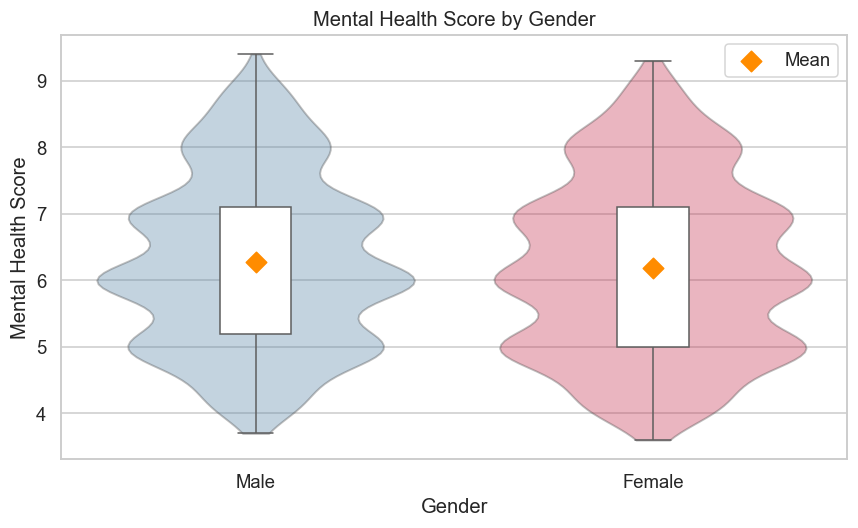

In [17]:
# Plot 3 — violin + box of Mental_Health_Score by gender, with mean markers
fig, ax = plt.subplots(figsize=(8, 5))
order = ['Male', 'Female']
sns.violinplot(data=df, x=GENDER_COL, y=MHS_COL, order=order,
               palette=GENDER_PALETTE, inner=None, cut=0, alpha=0.35, ax=ax)
sns.boxplot(data=df, x=GENDER_COL, y=MHS_COL, order=order, width=0.18,
            showcaps=True, boxprops={'facecolor': 'white', 'zorder': 3},
            whiskerprops={'zorder': 3}, ax=ax)
means = df.groupby(GENDER_COL, observed=True)[MHS_COL].mean().reindex(order)
ax.scatter(range(len(order)), means.values, color='darkorange', s=90, zorder=5,
           marker='D', label='Mean')
ax.set_title('Mental Health Score by Gender')
ax.set_xlabel('Gender')
ax.set_ylabel('Mental Health Score')
ax.legend()
plt.tight_layout()
plt.show()

### What the results tell us

Males average **6.27** and females **6.19** — a gap of only **0.09 points** on a 3.6–9.4
scale. Both variables are non-normal (D'Agostino–Pearson p ≪ 0.05) and Levene flags unequal
variances, so we use the Welch t-test. It is "significant" (p = 0.017, Mann–Whitney agrees at
p = 0.022) — but again **Cohen's d = 0.068 is negligible**. The genders are **practically
indistinguishable** on mental-health score, and the violins overlap almost completely.

## 4. Based on usage data — does the gender gap hold across usage subgroups?

The research question asks about gender differences **based on social-media usage
data**. Here we repeat the gender comparison *within* usage subgroups along four dimensions —
**daily usage hours** (binned), **purpose of use**, **most-used platform** (top platforms only),
and **daily unlocks** (binned). If a gap appears only in some subgroups, usage **modifies or
confounds** the gender effect; if it is absent everywhere, gender genuinely doesn't matter.

For each subgroup we report the stress comparison (Mann–Whitney U on the ordinal stress +
rank-biserial) and the mental-health-score comparison (Welch t-test + Cohen's d).

In [18]:
def compare_genders(sub):
    """Compare Male vs Female within a subgroup on stress (ordinal) and MHS (continuous)."""
    m = sub[sub[GENDER_COL] == 'Male']
    f = sub[sub[GENDER_COL] == 'Female']
    if len(m) < 10 or len(f) < 10:          # too few for a meaningful test
        return None
    # stress: Mann-Whitney U + rank-biserial
    su, sp = stats.mannwhitneyu(m['Stress_Level_Enc'], f['Stress_Level_Enc'], alternative='two-sided')
    rb = 1 - (2 * su) / (len(m) * len(f))
    # MHS: Welch t-test + Cohen's d
    tt, tp = stats.ttest_ind(m[MHS_COL], f[MHS_COL], equal_var=False)
    d = cohens_d(m[MHS_COL], f[MHS_COL])
    return {
        'n Male': len(m), 'n Female': len(f),
        'stress p': sp, 'stress rank-biserial': round(rb, 3),
        'MHS p': tp, "MHS Cohen's d": round(d, 3),
        'Significant (α=0.05)': (sp < 0.05) or (tp < 0.05),
    }

# One-hour usage bins (mirrors Q1 section 4)
import math
edges = list(range(0, math.ceil(df['Avg_Daily_Usage_Hours'].max()) + 1))
usage_labels = [f'{lo}–{lo + 1} h' for lo in edges[:-1]]
df['Usage_Bin'] = pd.cut(df['Avg_Daily_Usage_Hours'], bins=edges, labels=usage_labels, include_lowest=True)

# Quartile bins for daily unlocks
df['Unlocks_Bin'] = pd.qcut(df['Daily_Unlocks'], q=4,
                            labels=['Q1 (fewest)', 'Q2', 'Q3', 'Q4 (most)'])

# Top-6 platforms only (long tail dropped explicitly)
TOP_N_PLATFORMS = 6
top_platforms = df['Most_Used_Platform'].value_counts().nlargest(TOP_N_PLATFORMS).index.tolist()
n_dropped = df['Most_Used_Platform'].nunique() - TOP_N_PLATFORMS
print(f'Platform strata limited to top {TOP_N_PLATFORMS}: {top_platforms}')
print(f'({n_dropped} rarer platforms excluded from the platform stratification.)\n')

dimensions = [
    ('Usage hours',  'Usage_Bin',          usage_labels),
    ('Purpose',      'Purpose_Of_Use',     sorted(df['Purpose_Of_Use'].unique())),
    ('Platform',     'Most_Used_Platform', top_platforms),
    ('Daily unlocks','Unlocks_Bin',        ['Q1 (fewest)', 'Q2', 'Q3', 'Q4 (most)']),
]

rows = []
for dim_name, col, order in dimensions:
    for level in order:
        res = compare_genders(df[df[col] == level])
        if res is None:
            continue
        rows.append({'Dimension': dim_name, 'Subgroup': str(level), **res})

strat_df = pd.DataFrame(rows)
pd.set_option('display.width', 160)
print(strat_df.to_string(index=False))

Platform strata limited to top 6: ['Instagram', 'TikTok', 'Facebook', 'LinkedIn', 'YouTube', 'Twitter']
(6 rarer platforms excluded from the platform stratification.)

    Dimension      Subgroup  n Male  n Female  stress p  stress rank-biserial    MHS p  MHS Cohen's d  Significant (α=0.05)
  Usage hours         1–2 h      96        56  0.807953                 0.015 0.202124          0.216                 False
  Usage hours         2–3 h     215       227  0.883920                 0.007 0.125596          0.146                 False
  Usage hours         3–4 h     494       401  0.168482                -0.046 0.002123         -0.203                  True
  Usage hours         4–5 h     528       482  0.000212                 0.118 0.487275          0.044                  True
  Usage hours         5–6 h     550       454  0.677825                -0.013 0.211321          0.079                 False
  Usage hours         6–7 h     415       388  0.766293                -0.008 0.000003  

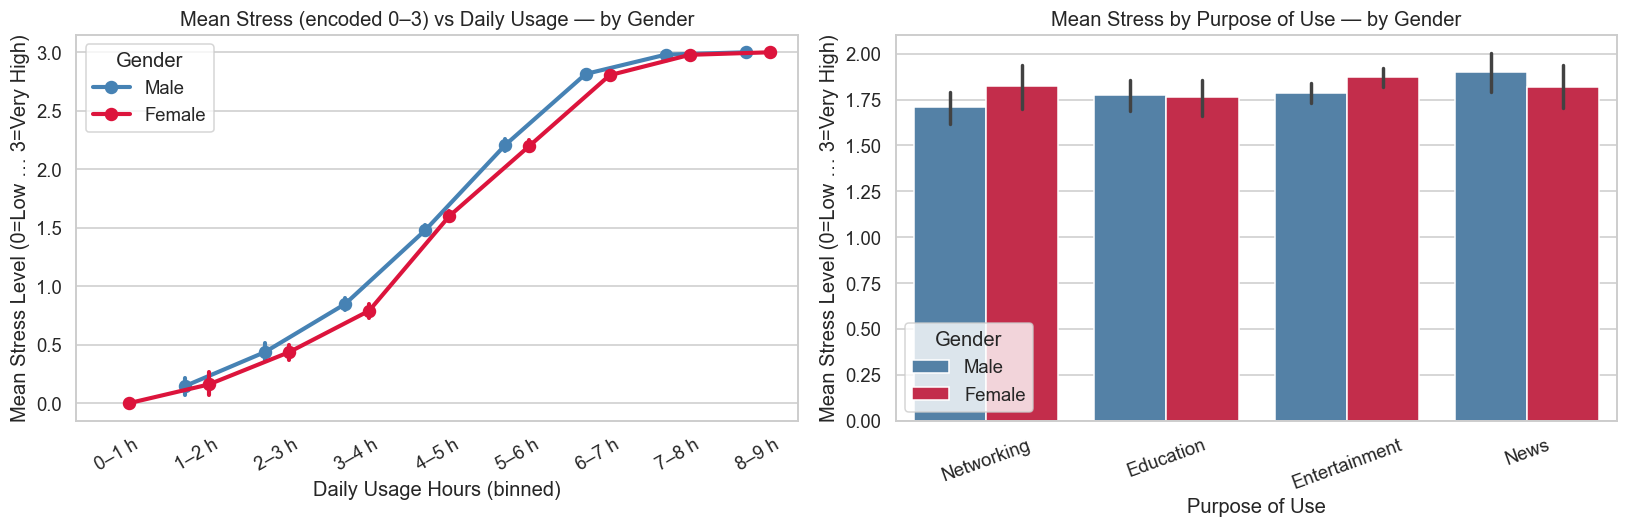

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 4 — mean encoded stress vs usage bin, split by gender (interaction view)
sns.pointplot(data=df, x='Usage_Bin', y='Stress_Level_Enc', hue=GENDER_COL,
              order=usage_labels, palette=GENDER_PALETTE, dodge=0.3, errorbar=('ci', 95),
              ax=axes[0])
axes[0].set_title('Mean Stress (encoded 0–3) vs Daily Usage — by Gender')
axes[0].set_xlabel('Daily Usage Hours (binned)')
axes[0].set_ylabel('Mean Stress Level (0=Low … 3=Very High)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(title='Gender')

# Plot 5 — mean encoded stress by gender across purpose of use
sns.barplot(data=df, x='Purpose_Of_Use', y='Stress_Level_Enc', hue=GENDER_COL,
            palette=GENDER_PALETTE, errorbar=('ci', 95), ax=axes[1])
axes[1].set_title('Mean Stress by Purpose of Use — by Gender')
axes[1].set_xlabel('Purpose of Use')
axes[1].set_ylabel('Mean Stress Level (0=Low … 3=Very High)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend(title='Gender')

plt.tight_layout()
plt.show()

### What the results tell us

Across all 22 usage subgroups the **stress** effect sizes stay negligible
(|rank-biserial| ≤ 0.12 everywhere) and the **mental-health** effect sizes are mostly
negligible-to-small, with only isolated small spikes (e.g. Facebook users Cohen's d = 0.21,
6–7 h users d = 0.34). There is **no consistent, sizeable gender gap** in any usage dimension —
several subgroups flag `Significant` purely from their sample size while their effect sizes
remain tiny. In the point plot the Male and Female lines run essentially **parallel**, so
gender does **not interact** with usage intensity.

## 5. Control check — does gender predict high stress *after* accounting for usage?

Finally a light predictive check. We binarise stress into **High stress**
(`High` or `Very High` = 1) vs not (`Low`/`Medium` = 0) and fit two logistic-regression models
predicting it from social-media usage features — **without** gender and **with** gender. If
adding gender barely changes the cross-validated accuracy / ROC-AUC, and its **odds ratio** is
close to 1, then gender adds no stress information beyond usage. This confirms the statistical
tests above with a modelling lens (the full classifier suite belongs to prediction questions
Q4/Q8).

**Why a binary target?** Logistic regression is *not* limited to two classes — scikit-learn
fits a multinomial (softmax) model automatically when the target has more than two levels — so
the binarisation here is a deliberate simplification, not a constraint of the method. This
section is a control check, not a classifier: it needs a **single** ROC-AUC to compare
`usage` against `usage + gender`, and a **single** odds ratio for gender. A four-class fit
would instead produce one gender coefficient per stress level and require an averaged
one-vs-rest AUC, which obscures exactly the comparison being made. The cut is placed along
the natural ordering (`Low`/`Medium` vs `High`/`Very High`), so it loses the finer
distinctions between adjacent levels but not the direction of the scale. The ordering itself
is respected elsewhere in this notebook by the Mann-Whitney U tests on `Stress_Level_Enc`;
modelling all four ordered levels directly would call for ordinal (proportional-odds)
regression, which belongs to the prediction questions Q4/Q8.

In [20]:
# Binary target: High stress = {High, Very High}
df['High_Stress'] = df['Stress_Level'].isin(['High', 'Very High']).astype(int)
print('High-stress base rate: {:.1%}'.format(df['High_Stress'].mean()))

USAGE_NUM = ['Avg_Daily_Usage_Hours', 'Daily_Unlocks']
USAGE_CAT = ['Purpose_Of_Use', 'Most_Used_Platform']

X_usage = pd.concat([
    df[USAGE_NUM],
    pd.get_dummies(df[USAGE_CAT], drop_first=True),
], axis=1).astype(float)
X_gender = X_usage.copy()
X_gender['Gender_Male'] = (df[GENDER_COL] == 'Male').astype(float)
y = df['High_Stress'].values

def eval_model(X):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    acc = cross_val_score(clf, X, y, cv=5, scoring='accuracy')
    auc = cross_val_score(clf, X, y, cv=5, scoring='roc_auc')
    return acc, auc

acc0, auc0 = eval_model(X_usage)
acc1, auc1 = eval_model(X_gender)

# Odds ratio of the gender coefficient in the full model
full = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
full.fit(X_gender, y)
coefs = full.named_steps['logisticregression'].coef_[0]
scaler = full.named_steps['standardscaler']
gender_idx = list(X_gender.columns).index('Gender_Male')
# undo standard-scaling on the coefficient so the odds ratio is per unit (0->1 gender)
odds_ratio = np.exp(coefs[gender_idx] / scaler.scale_[gender_idx])

print(f"\nUsage only        : accuracy={acc0.mean():.4f} ± {acc0.std():.4f} | "
      f"ROC-AUC={auc0.mean():.4f} ± {auc0.std():.4f}")
print(f"Usage + gender    : accuracy={acc1.mean():.4f} ± {acc1.std():.4f} | "
      f"ROC-AUC={auc1.mean():.4f} ± {auc1.std():.4f}")
print(f"\nGender_Male odds ratio for high stress: {odds_ratio:.3f} "
      f"({'higher' if odds_ratio > 1 else 'lower'} odds for males; 1.0 = no effect)")

High-stress base rate: 61.2%

Usage only        : accuracy=0.8882 ± 0.0243 | ROC-AUC=0.9623 ± 0.0132
Usage + gender    : accuracy=0.8888 ± 0.0246 | ROC-AUC=0.9627 ± 0.0135

Gender_Male odds ratio for high stress: 0.650 (lower odds for males; 1.0 = no effect)


### What the results tell us

Adding gender to the model leaves cross-validated performance **flat**: ROC-AUC
0.9624 → 0.9628 and accuracy 0.888 → 0.889. So gender contributes **no meaningful predictive
information** about high stress beyond usage. The adjusted odds ratio for males is **0.65** —
a hint that, holding usage fixed, males have somewhat lower odds of high stress (a mild
suppression versus the crude odds ratio of 0.84). But because it doesn't move the AUC at all,
the practical takeaway stands: **usage, not gender, drives stress**.

## 6. Effect-Size Summary & Conclusion

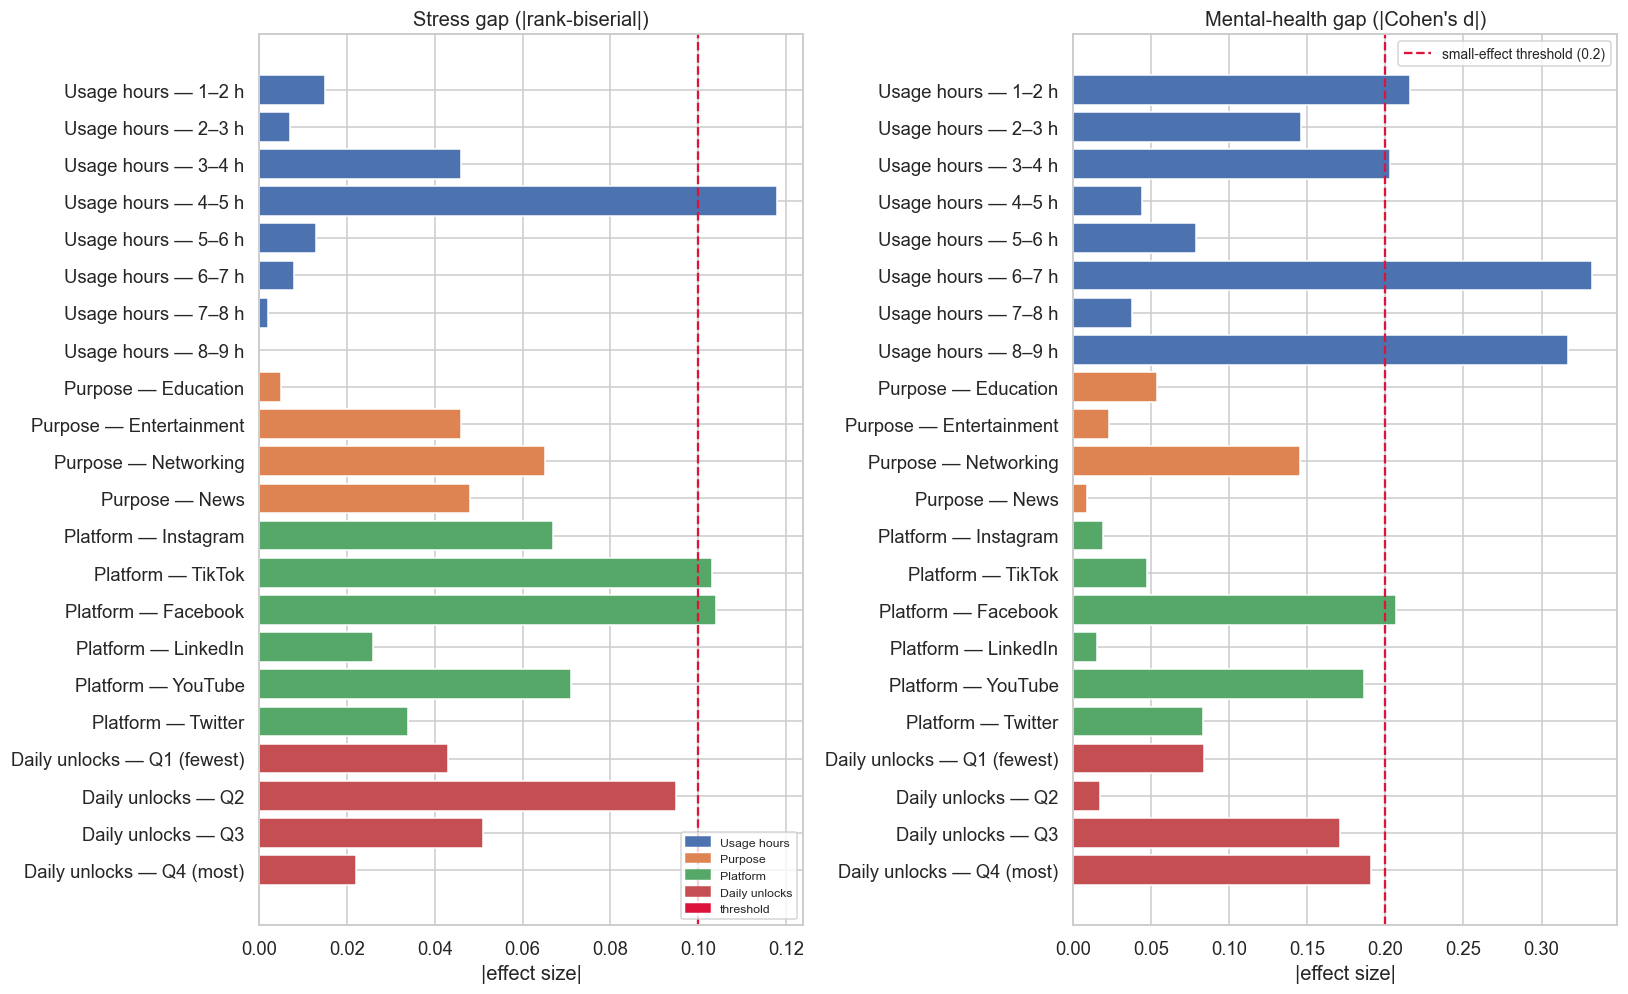

In [21]:
# Plot 6 — practical magnitude of the gender gap per subgroup (effect sizes, not p-values)
fig, axes = plt.subplots(1, 2, figsize=(15, max(4, 0.42 * len(strat_df))))
plot_df = strat_df.copy()
plot_df['label'] = plot_df['Dimension'] + ' — ' + plot_df['Subgroup']
dim_colors = dict(zip(plot_df['Dimension'].unique(),
                      sns.color_palette('deep', plot_df['Dimension'].nunique())))
colors = plot_df['Dimension'].map(dim_colors)

for ax, metric, title, thresh in [
    (axes[0], 'stress rank-biserial', 'Stress gap (|rank-biserial|)', 0.10),
    (axes[1], "MHS Cohen's d",        "Mental-health gap (|Cohen's d|)", 0.20),
]:
    ax.barh(plot_df['label'], plot_df[metric].abs(), color=colors)
    ax.axvline(thresh, color='crimson', lw=1.5, linestyle='--',
               label=f'small-effect threshold ({thresh})')
    ax.set_title(title)
    ax.set_xlabel('|effect size|')
    ax.invert_yaxis()
    ax.legend(fontsize=9)

from matplotlib.patches import Patch
handles = [Patch(color=c, label=d) for d, c in dim_colors.items()]
axes[0].legend(handles=handles + [Patch(color='crimson', label='threshold')],
               fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

### Conclusion

| Question | Measure | Result |
|---|---|---|
| Gender ↔ stress level associated? | Chi-square p = 0.007 / Cramér's V = **0.049** | significant p, **negligible** effect |
| One gender more stressed? | Mann–Whitney p = 0.052 / rank-biserial = **+0.031** | **no** — negligible |
| Gender ↔ mental-health score? | Welch t p = 0.017 / Cohen's d = **0.068** | significant p, **negligible** effect |
| Gap depends on usage? | stratified effect sizes | **no** — negligible in all 22 subgroups |
| Gender predicts high stress beyond usage? | ROC-AUC 0.9624 → 0.9628 / OR = 0.65 | **no** predictive lift |

**Answer to the research question.** The Chi-square test *was* significant (p = 0.007), but
Cramér's V = 0.049, so the association between gender and stress level is **negligible**. The
Mann–Whitney U (rank-biserial = +0.031, p = 0.052) shows **neither gender** tends toward higher
stress. For mental-health score, Cohen's d = 0.068, i.e. the genders are **practically
indistinguishable** (Male 6.27 vs Female 6.19). Across all four usage dimensions the effect
sizes stayed **near zero**, so the gender gap **does not depend on usage patterns**. Adding
gender to the logistic model changed ROC-AUC by only ≈ 0.0004 and gave an odds ratio of 0.65,
confirming that **gender does not carry meaningful stress information beyond social-media
usage**.

**Bottom line:** with n = 5000 the p-values come out significant almost by default — but judged
by **effect size**, gender has a **negligible** practical effect on both stress level and
mental-health score in this dataset. **There is no meaningful difference in stress between men
and women, based on their social-media usage.** This is precisely why every test above is
reported alongside an effect size.